# DS-471 Machine Learning Project: Heart Failure Prediction

## Stage 1: Data Cleaning, Preparation and Exploration

In [5]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [6]:
# Load dataset
df = pd.read_csv('/content/heart_failure_clinical_records_dataset.csv')
print('Shape:', df.shape)
print('\nData types:\n', df.dtypes)
print('\nFirst 5 rows:')
display(df.head())
print('\nSummary statistics:')
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Shape: (299, 13)

Data types:
 age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

First 5 rows:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Summary statistics:


,count,mean,std,min,50%,max
age,299.0,60.83,11.89,40.0,60.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,250.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,38.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,262000.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,1.1,9.4
serum_sodium,299.0,136.63,4.41,113.0,137.0,148.0
sex,299.0,0.65,0.48,0.0,1.0,1.0


In [7]:
# Check missing values and duplicates
print('Missing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

# Fix decimal age values (rows 185 and 188 have 60.667)
df_clean = df.copy()
print('\nDecimal ages before cleaning:')
print(df_clean[df_clean['age'] % 1 != 0][['age', 'sex', 'DEATH_EVENT']])
df_clean['age'] = df_clean['age'].round().astype(int)

# Check outliers using IQR rule
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time']
print('\nOutliers and skewness:')
for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    out_count = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f'{col:25s} | Outliers={out_count:2d} | Skew={df_clean[col].skew():+.2f}')

Missing values:
 age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Duplicate rows: 0

Decimal ages before cleaning:
        age  sex  DEATH_EVENT
185  60.667    1            1
188  60.667    0            0

Outliers and skewness:
age                       | Outliers= 0 | Skew=+0.42
creatinine_phosphokinase  | Outliers=29 | Skew=+4.46
ejection_fraction         | Outliers= 2 | Skew=+0.56
platelets                 | Outliers=21 | Skew=+1.46
serum_creatinine          | Outliers=29 | Skew=+4.46
serum_sodium              | Outliers= 4 | Skew=-1.05
time                      | Outliers= 0 | Skew=+0.13


Survived (0): 203 (67.89%)
Deceased (1): 96 (32.11%)


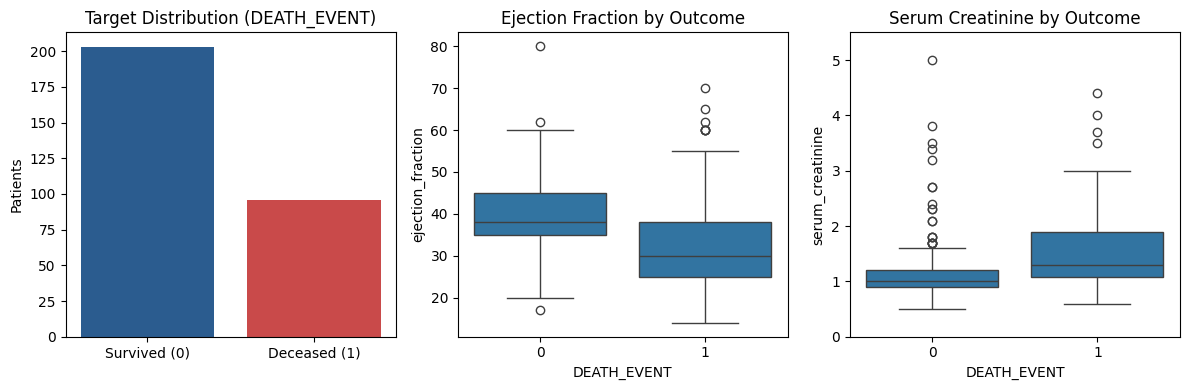

In [8]:
# Feature engineering
df_fe = df_clean.copy()
df_fe['log_cpk'] = np.log1p(df_fe['creatinine_phosphokinase'])
df_fe['log_serum_creatinine'] = np.log1p(df_fe['serum_creatinine'])
df_fe['creatinine_sodium_ratio'] = df_fe['serum_creatinine'] / (df_fe['serum_sodium'] / 100.0)
df_fe['ef_age_ratio'] = df_fe['ejection_fraction'] / df_fe['age']

# Target distribution and boxplots
counts = df_fe['DEATH_EVENT'].value_counts().sort_index()
print(f"Survived (0): {counts[0]} ({counts[0]/len(df_fe)*100:.2f}%)")
print(f"Deceased (1): {counts[1]} ({counts[1]/len(df_fe)*100:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].bar(['Survived (0)', 'Deceased (1)'], counts.values, color=['#2b5c8f', '#c94a4a'])
axes[0].set_title('Target Distribution (DEATH_EVENT)')
axes[0].set_ylabel('Patients')

sns.boxplot(data=df_fe, x='DEATH_EVENT', y='ejection_fraction', ax=axes[1])
axes[1].set_title('Ejection Fraction by Outcome')

sns.boxplot(data=df_fe, x='DEATH_EVENT', y='serum_creatinine', ax=axes[2])
axes[2].set_title('Serum Creatinine by Outcome')
axes[2].set_ylim(0, 5.5)
plt.tight_layout()
plt.show()

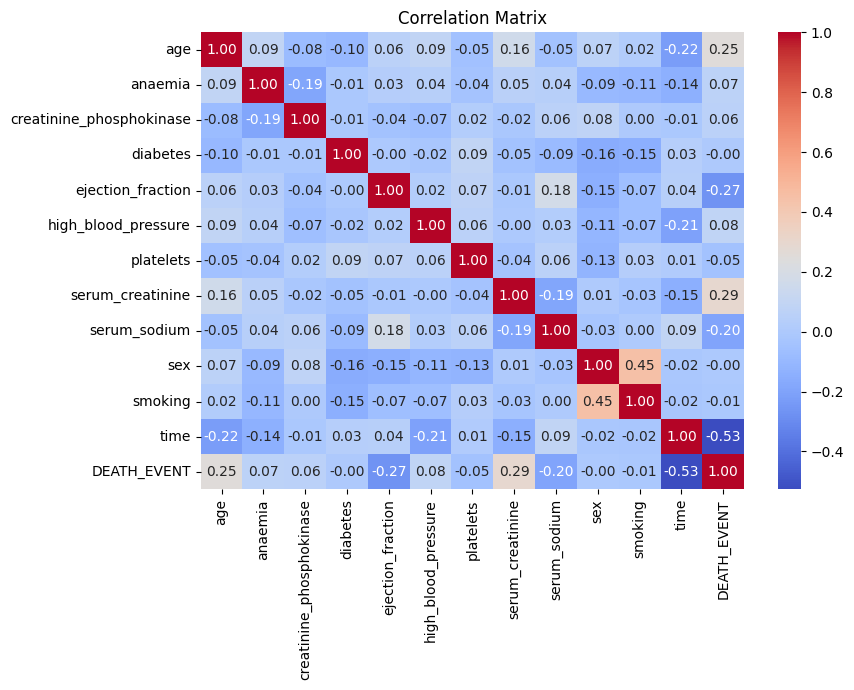

Top features correlated with DEATH_EVENT:
 time                       -0.5270
ef_age_ratio               -0.3553
log_serum_creatinine        0.3461
creatinine_sodium_ratio     0.2993
serum_creatinine            0.2943
ejection_fraction          -0.2686
age                         0.2538
serum_sodium               -0.1952
high_blood_pressure         0.0844
anaemia                     0.0663
creatinine_phosphokinase    0.0627
platelets                  -0.0491
log_cpk                     0.0320
smoking                    -0.0126
sex                        -0.0043
diabetes                   -0.0019
Name: DEATH_EVENT, dtype: float64


In [9]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Most relevant features by correlation with DEATH_EVENT
corrs = df_fe.corr()['DEATH_EVENT'].drop('DEATH_EVENT').sort_values(key=abs, ascending=False)
print('Top features correlated with DEATH_EVENT:\n', corrs.round(4))

## Stage 2: Data Splitting and Scaling

In [10]:
# Separate features (X) and target (y)
X = df_fe.drop('DEATH_EVENT', axis=1)
y = df_fe['DEATH_EVENT']

# Stratified split: 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Fit StandardScaler ONLY on training data
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

print('Train:', X_train.shape, '| Deaths:', y_train.sum())
print('Val  :', X_val.shape, '| Deaths:', y_val.sum())
print('Test :', X_test.shape, '| Deaths:', y_test.sum())

Train: (209, 16) | Deaths: 67
Val  : (45, 16) | Deaths: 15
Test : (45, 16) | Deaths: 14


## Stage 3 & Stage 4: Model Development, Training and Hyperparameter Tuning

### Model 1: Decision Tree

In [11]:
# Check overfitting with a deep tree
dt_deep = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_deep.fit(X_train_sc, y_train)
print('Deep DT Train Acc:', round(accuracy_score(y_train, dt_deep.predict(X_train_sc)), 4))
print('Deep DT Val Acc  :', round(accuracy_score(y_val, dt_deep.predict(X_val_sc)), 4))

# Tune Decision Tree with 5-fold cross-validation
dt_params = {'max_depth': [2, 3, 4, 5], 'min_samples_split': [2, 6, 10]}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_params, cv=5, scoring='roc_auc')
dt_grid.fit(X_train_sc, y_train)

dt_model = dt_grid.best_estimator_
print('Best DT params:', dt_grid.best_params_)
print('Tuned DT Train Acc:', round(accuracy_score(y_train, dt_model.predict(X_train_sc)), 4))
print('Tuned DT Val Acc  :', round(accuracy_score(y_val, dt_model.predict(X_val_sc)), 4))

Deep DT Train Acc: 1.0
Deep DT Val Acc  : 0.7556
Best DT params: {'max_depth': 2, 'min_samples_split': 2}
Tuned DT Train Acc: 0.866
Tuned DT Val Acc  : 0.8


### Model 2: Random Forest

Deep RF Train Acc: 1.0
Deep RF Val Acc  : 0.8444
Best RF params: {'max_depth': 4, 'min_samples_split': 4, 'n_estimators': 50}
Tuned RF Train Acc: 0.933
Tuned RF Val Acc  : 0.8444


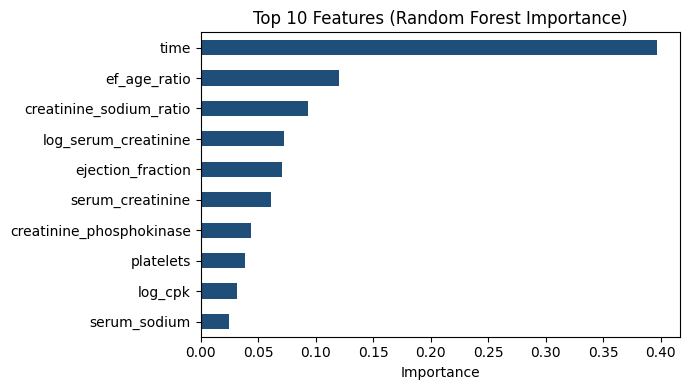

In [12]:
# Check overfitting with deep trees
rf_deep = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
rf_deep.fit(X_train_sc, y_train)
print('Deep RF Train Acc:', round(accuracy_score(y_train, rf_deep.predict(X_train_sc)), 4))
print('Deep RF Val Acc  :', round(accuracy_score(y_val, rf_deep.predict(X_val_sc)), 4))

# Tune Random Forest with 5-fold cross-validation
rf_params = {'n_estimators': [50, 100, 150], 'max_depth': [3, 4, 5, 6], 'min_samples_split': [4, 6]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='roc_auc')
rf_grid.fit(X_train_sc, y_train)

rf_model = rf_grid.best_estimator_
print('Best RF params:', rf_grid.best_params_)
print('Tuned RF Train Acc:', round(accuracy_score(y_train, rf_model.predict(X_train_sc)), 4))
print('Tuned RF Val Acc  :', round(accuracy_score(y_val, rf_model.predict(X_val_sc)), 4))

# Plot top 10 feature importances
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind='barh', color='#1f4e78', figsize=(7, 4), title='Top 10 Features (Random Forest Importance)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### Model 3: Mandatory Neural Network (MLP with Keras)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Stopped at epoch: 77
NN Train Acc: 0.9091
NN Val Acc  : 0.8444


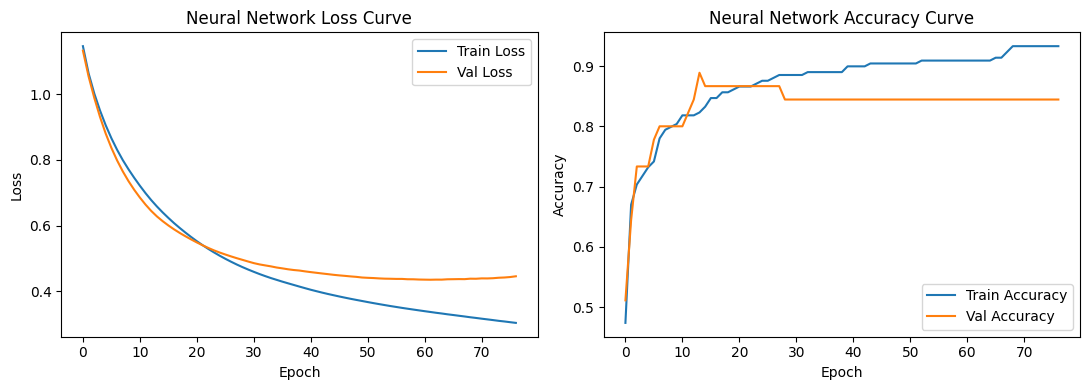

In [13]:
# Build Neural Network with L2 regularization
nn_model = Sequential([
    Dense(32, activation='relu', kernel_regularizer=l2(0.01), input_shape=(X_train_sc.shape[1],)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = nn_model.fit(
    X_train_sc, y_train,
    validation_data=(X_val_sc, y_val),
    epochs=120,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

print('Stopped at epoch:', len(history.history['loss']))
print('NN Train Acc:', round(nn_model.evaluate(X_train_sc, y_train, verbose=0)[1], 4))
print('NN Val Acc  :', round(nn_model.evaluate(X_val_sc, y_val, verbose=0)[1], 4))

# Plot Training and Validation Loss & Accuracy Curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Neural Network Loss Curve')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Neural Network Accuracy Curve')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()
plt.tight_layout()
plt.show()

## Stage 5: Final Model Evaluation and Comparison

In [14]:
# Predict probabilities on the unseen Test Set
dt_prob = dt_model.predict_proba(X_test_sc)[:, 1]
rf_prob = rf_model.predict_proba(X_test_sc)[:, 1]
nn_prob = nn_model.predict(X_test_sc, verbose=0).ravel()

# Build final comparison table
models_eval = [
    ('Decision Tree', dt_prob),
    ('Random Forest', rf_prob),
    ('Neural Network (MLP)', nn_prob)
]

results = []
for name, probs in models_eval:
    preds = (probs >= 0.5).astype(int)
    results.append({
        'Model': name,
        'Test Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.8222,0.7500,0.6429,0.6923,0.7776
1,Random Forest,0.7778,0.6250,0.7143,0.6667,0.8134
2,Neural Network (MLP),0.8000,0.7273,0.5714,0.6400,0.7995


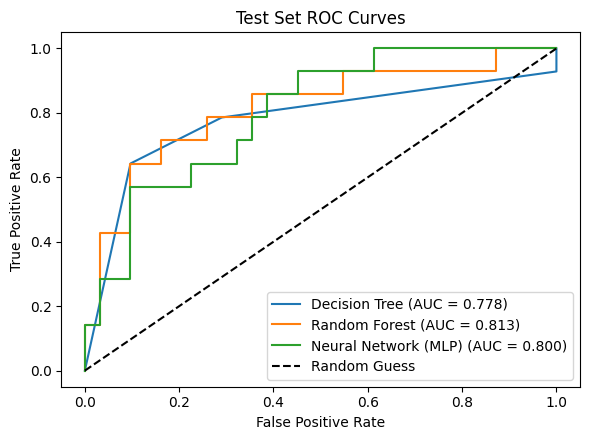

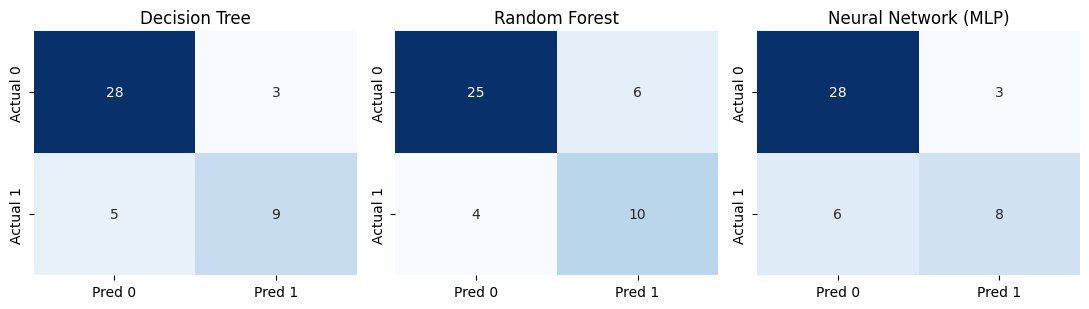

In [15]:
# Plot ROC Curves and Confusion Matrices on Test Set
plt.figure(figsize=(6, 4.5))
for name, probs in models_eval:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Test Set ROC Curves'); plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (name, probs) in zip(axes, models_eval):
    cm = confusion_matrix(y_test, (probs >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
    ax.set_title(name)
plt.tight_layout()
plt.show()